In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("ML environment ready")

ML environment ready


In [2]:
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [17]:
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
    dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
    db = (-2/len(x))*np.sum(y_demo-yhat)
    m -= lr*dm
    b -= lr*db
    print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))

0.44 0.12
0.78 0.21
1.03 0.28
1.23 0.33
1.38 0.37
1.49 0.4
1.58 0.42
1.65 0.44
1.7 0.45
1.74 0.46
1.77 0.47
1.79 0.47
1.81 0.48
1.82 0.48
1.83 0.48
1.84 0.48
1.85 0.48
1.85 0.48
1.86 0.48
1.86 0.48
1.86 0.48
1.86 0.48
1.86 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.45
1.87 0.45
1.88 0.45
1.88 0.45
1.88 0.45
1.88 0.45
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.38
1.89 0.38
1.89 0.38
1.89 0.38
1.89 0.38
1.9 0.38
1.9 0.38
1.9 0.38
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.36
1.

In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score 

models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(name, "R2:", round(r2_score(y_test, p), 3))

Ridge R2: 0.454
Lasso R2: 0.456
ElasticNet R2: 0.459


In [22]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())


                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        13:46:11   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

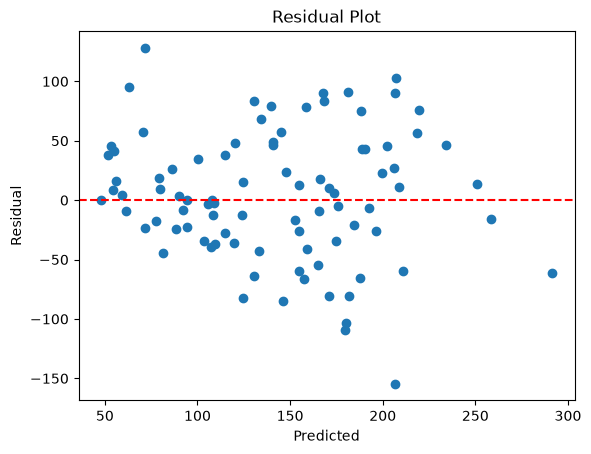

In [23]:
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
for degree in [1, 2, 5, 10]:
    model = make_pipeline(
    PolynomialFeatures(degree),
    LinearRegression()
    )
    model.fit(X_train[["bmi"]], y_train)
    tr = model.predict(X_train[["bmi"]])
    te = model.predict(X_test[["bmi"]])
    print(degree,
    mean_squared_error(y_train,tr),
    mean_squared_error(y_test,te))

1 3854.11265207582 4061.8259284949268
2 3849.3331334111795 4085.025480871632
5 3823.763813306945 4085.845566850978
10 3815.5854342370912 3979.509532458032


In [25]:
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)
mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 42.79409467959994
MSE: 2900.1936284934804
RMSE: 53.85344583676592
R2: 0.4526027629719196
